In [1]:
# Arquivos de dados experimentais
!wget https://raw.githubusercontent.com/cagliarijv/Minicurso_simulacao_cromatina/principal/chr10_100k.dense
!wget https://raw.githubusercontent.com/cagliarijv/Minicurso_simulacao_cromatina/principal/chr10_100k.eigen

--2026-10-16 11:20:27--  https://raw.githubusercontent.com/cagliarijv/Minicurso_simulacao_cromatina/principal/chr10_100k.dense
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 2606:50c0:8000::154, 2606:50c0:8001::154, 2606:50c0:8002::154, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|2606:50c0:8000::154|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 17117394 (16M) [text/plain]
Saving to: ‘chr10_100k.dense.1’

chr10_100k.dense.1  100%[===================>]  16.32M  39.4MB/s    in 0.4s    

2026-10-16 11:20:28 (39.4 MB/s) - ‘chr10_100k.dense.1’ saved [17117394/17117394]

--2026-10-16 11:20:28--  https://raw.githubusercontent.com/cagliarijv/Minicurso_simulacao_cromatina/principal/chr10_100k.eigen
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 2606:50c0:8000::154, 2606:50c0:8001::154, 2606:50c0:8002::154, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|2606:50c0:8000::154|:443

In [ ]:
# Instalações necessárias
!pip install OpenMiChroM
!pip install openmm simtk
!pip install mdtraj
!pip install matplotlib
!pip install imageio

In [1]:
# Bibliotecas usadas
from sklearn.preprocessing import normalize
from OpenMiChroM.ChromDynamics import MiChroM
from OpenMiChroM.CndbTools import cndbTools
from matplotlib.cm import ScalarMappable
from IPython.display import Image
import matplotlib.pyplot as plt
import matplotlib as mpl
cndbTools = cndbTools()
from openmm import unit
import mdtraj as md
import pandas as pd
import numpy as np
import imageio
import os

print('Bibliotecas instaladas e baixadas')

Bibliotecas instaladas e baixadas


Número de beads:  1356


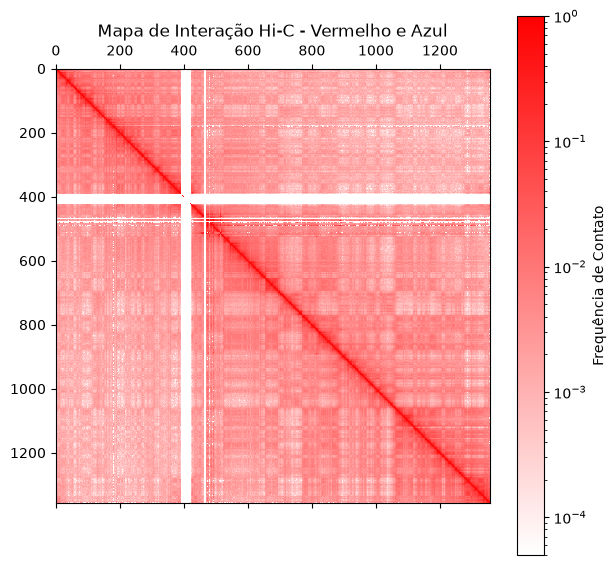

In [2]:
# Parâmetros de tamanho da imagem (modifique conforme necessário)
fig_width = 7  # Largura da figura
fig_height = 7  # Altura da figura

# Carregando o arquivo de Hi-C
#filename = '/content/chr10_100k.dense'
filename = 'chr10_100k.dense'
hic_file = np.loadtxt(filename)

r = np.triu(hic_file, k=1)  # Mantendo valores da metade superior
r[np.isnan(r)] = 0.0  # Substituindo NaN por zero
r = normalize(r, axis=1, norm='max')  # Normalizando os valores
rd = np.transpose(r)  # Transposição para simetria
r = r + rd + np.diag(np.ones(len(r)))  # Adicionando diagonal de 1s

print("Número de beads: ", len(r))

# Criando colormap personalizado (azul → branco → vermelho)
vmax = r.max()
vmin = 0.00005

colors = [[0, "blue"],  # Mínimo
          [0.5, "white"],  # Valor intermediário
          [1, "red"]]  # Máximo

colors = [[0, "white"],  # Mínimo
          [1, "red"]]  # Máximo

cmap = mpl.colors.LinearSegmentedColormap.from_list("custom_cmap", colors)

# Criando a figura com tamanho personalizado
fig = plt.figure(figsize=(fig_width, fig_height))
ax = fig.add_subplot(111)  # Adicionando eixos

# Criando gráfico com padrão de cores ajustado
im = ax.matshow(r, norm=mpl.colors.LogNorm(vmin=vmin, vmax=vmax), cmap=cmap)
plt.colorbar(im, label="Frequência de Contato")

plt.title("Mapa de Interação Hi-C - Vermelho e Azul")
plt.show()

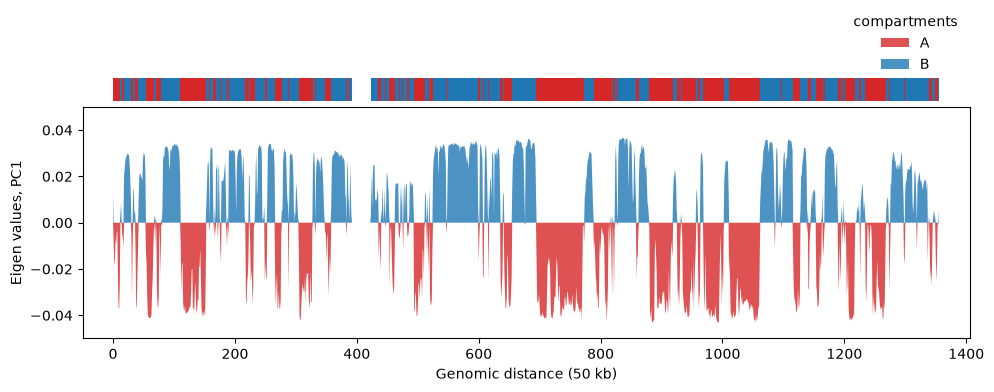

In [3]:
# Carregando arquivo .eigen
# eigen = np.loadtxt('/content/chr10_100k.eigen')
eigen = np.loadtxt('chr10_100k.eigen')

# Processando dados
index = np.arange(eigen.size)
df = pd.Series(eigen, index=index)

A1_df = pd.Series(np.zeros(eigen.size), index=index)
A1_df[df < 0] = df[df < 0]
B1_df = pd.Series(np.zeros(eigen.size), index=index)
B1_df[df > 0] = df[df > 0]


# Gerando gráfico
fig, axes = plt.subplots(ncols=1, nrows=2, figsize=(6.4 * 3 / 2, 4.8 * 2 / 3), gridspec_kw={'height_ratios': [1, 10]})
fig.tight_layout()
fig.subplots_adjust(hspace=0.05)

# Sequência
A11_df = A1_df.copy()
A11_df[A1_df < 0] = 1
B11_df = B1_df.copy()
B11_df[B1_df > 0] = 1

axes[0].axis('off')
width = 1
axes[0].bar(A11_df.index, A11_df, width, color="tab:red")
axes[0].bar(B11_df.index, B11_df, width, color="tab:blue")
axes[0].set_xlim([-50, eigen.size + 50])

# Eigen PC1
step = 1
axes[1].fill_between(A1_df.index[::step], A1_df[::step], 0, facecolor="tab:red", alpha=0.8, label="A")
axes[1].fill_between(B1_df.index[::step], B1_df[::step], 0, facecolor="tab:blue", alpha=0.8, label="B")

axes[1].set_ylim([-0.05, 0.05])
axes[1].set_xlim([-50, eigen.size + 50])
axes[1].set_ylabel('Eigen values, PC1')
axes[1].set_xlabel('Genomic distance (50 kb)')
axes[1].legend(title='compartments', bbox_to_anchor=(1., 1.45), frameon=False)

In [4]:
# Inicializa a simulação para o cromossomo 10
sim_chr10 = MiChroM(name="chr10", temperature=1.0, timeStep=0.01)

    ***************************************************************************************     
     **** **** *** *** *** *** *** *** OpenMiChroM-1.1.1 *** *** *** *** *** *** **** ****      

         OpenMiChroM is a Python library for performing chromatin dynamics simulations.         
                            OpenMiChroM uses the OpenMM Python API,                             
                employing the MiChroM (Minimal Chromatin Model) energy function.                
      The chromatin dynamics simulations generate an ensemble of 3D chromosomal structures      
      that are consistent with experimental Hi-C maps, also allows simulations of a single      
                 or multiple chromosome chain using High-Performance Computing                  
                            in different platforms (GPUs and CPUs).                             

         OpenMiChroM documentation is available at https://open-michrom.readthedocs.io          

         OpenMiChroM is des

In [6]:
# Configura a plataforma de simulação
# sim_chr10.setup(platform="CPU")  # CUDA, HIP, CPU, OpenCL
sim_chr10.setup(platform="OpenCL", gpu="default", integrator="langevin", precision="single", deviceIndex="0")

Using platform: OpenCL


In [7]:
# Define a pasta onde os dados da simulação serão salvos
sim_chr10.saveFolder('output_chr10')
print('Pasta output_chr10 criada, verifique a esqueda da tela')

Pasta output_chr10 criada, verifique a esqueda da tela


In [8]:
# Criando o arquivo e escrevendo o conteúdo
with open('chr10_beads.txt', "w") as file:
        file.write("""1 NA\n2 NA\n3 B1\n4 B1\n5 B1\n6 B1\n7 B1\n8 B1\n9 B1\n10 B1
    11 B1\n12 B1\n13 B1\n14 B1\n15 B1\n16 B1\n17 B1\n18 B1\n19 A1\n20 A1
    21 A1\n22 A1\n23 B1\n24 B1\n25 B1\n26 B1\n27 B1\n28 B1\n29 B1\n30 B1
    31 B1\n32 B1\n33 B1\n34 B1\n35 B1\n36 B1\n37 B2\n38 B2\n39 B2\n40 B2
    41 B2\n42 B2\n43 B2\n44 B2\n45 B2\n46 B2\n47 B2\n48 B2\n49 B2\n50 B2
    51 B2\n52 B2\n53 B2\n54 B2\n55 B2\n56 B2\n57 B2\n58 B2\n59 B2\n60 B2
    61 B1\n62 B1\n63 A2\n64 A2\n65 B1\n66 B1\n67 B2\n68 B2\n69 B2\n70 B2
    71 B1\n72 B1\n73 B2\n74 B2\n75 B1\n76 B1\n77 A2\n78 A2\n79 A2\n80 A2
    81 A2\n82 A2\n83 B1\n84 B1\n85 B2\n86 B2\n87 B2\n88 B2\n89 B2\n90 B2
    91 B2\n92 B2\n93 B2\n94 B2\n95 B2\n96 B2\n97 B2\n98 B2\n99 B2\n100 B2
    101 B2\n102 B2\n103 B2\n104 B2\n105 B2\n106 B2\n107 B2\n108 B2\n109 B1\n110 B1
    111 B1\n112 B1\n113 A2\n114 A2\n115 A2\n116 A2\n117 A1\n118 A1\n119 A1\n120 A1
    121 A2\n122 A2\n123 A2\n124 A2\n125 A2\n126 A2\n127 A2\n128 A2\n129 A2\n130 A2
    131 B1\n132 B1\n133 B1\n134 B1\n135 B1\n136 B1\n137 B2\n138 B2\n139 B1\n140 B1
    141 B2\n142 B2\n143 B2\n144 B2\n145 A2\n146 A2\n147 A2\n148 A2\n149 A2\n150 A2
    151 A2\n152 A2\n153 B2\n154 B2\n155 B2\n156 B2\n157 A2\n158 A2\n159 B2\n160 B2
    161 B2\n162 B2\n163 B2\n164 B2\n165 B2\n166 B2\n167 B2\n168 B2\n169 B2\n170 B2
    171 B2\n172 B2\n173 B2\n174 B2\n175 B2\n176 B2\n177 B2\n178 B2\n179 B2\n180 B2
    181 B2\n182 B2\n183 B2\n184 B2\n185 B2\n186 B2\n187 B2\n188 B2\n189 B2\n190 B2
    191 B2\n192 B2\n193 B2\n194 B2\n195 B2\n196 B2\n197 B2\n198 B2\n199 B2\n200 B2
    201 B2\n202 B2\n203 B2\n204 B2\n205 B2\n206 B2\n207 B2\n208 B2\n209 B2\n210 B2
    211 B2\n212 B2\n213 B2\n214 B2\n215 B2\n216 B2\n217 B2\n218 B2\n219 B2\n220 B2
    221 B2\n222 B2\n223 B2\n224 B2\n225 A2\n226 A2\n227 A2\n228 A2\n229 A2\n230 A2""")

print("Arquivo 'chr10_beads.txt' criado com sucesso!")

Arquivo 'chr10_beads.txt' criado com sucesso!


In [9]:
# Define o caminho completo para o arquivo
#file_path = '/content/chr10_beads.txt'
file_path = 'chr10_beads.txt'

# Cria a estrutura espiral usando o arquivo do Drive
chr10 = sim_chr10.createRandomWalk(ChromSeq=file_path)

In [10]:
# Carrega a estrutura da cromatina no simulador
sim_chr10.loadStructure(chr10, center=True)

In [11]:
# Adiciona várias forças e potenciais ao sistema
sim_chr10.addFENEBonds(kFb=30.0)
sim_chr10.addAngles(kA=2.0)
sim_chr10.addRepulsiveSoftCore(eCut=4.0)
sim_chr10.addFlatBottomHarmonic()
sim_chr10.addTypetoType(mu=3.22, rc=1.78)
sim_chr10.addIdealChromosome(mu=3.22, rc=1.78, dinit=3, dend=200)

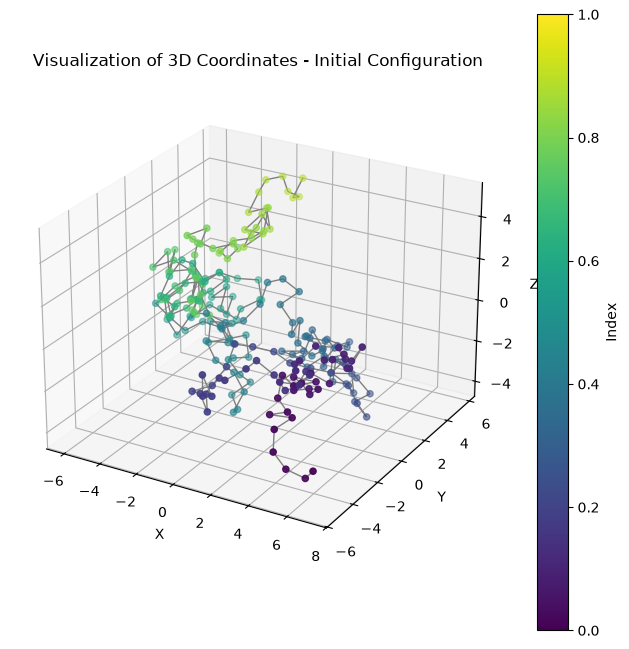

In [12]:
# Extraindo as dados de cordenadas
data = chr10

# Descompacte em listas separadas para facilitar a plotagem
x, y, z = zip(*data)

# Criar um mapa de cores
cmap = plt.cm.viridis  # Escolha um mapa de cores que você goste

# Crie a figura 3D e os eixos
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')

# Trace os pontos com cores com base no índice
colors = cmap(range(len(x)))  # Gerar cores com base no número de pontos

# Trace os pontos de dispersão
p = ax.scatter(x, y, z, c=colors, marker='.', s=80)

ax.plot(x, y, z, color='gray', linewidth=1)


# ax.set_xlim(-15, 15)
# ax.set_ylim(-15, 15)
# ax.set_zlim(-15, 15)

sm = ScalarMappable(cmap=cmap)
sm.set_array([])
fig.colorbar(sm, ax=ax, label='Index')

# Personalize rótulos, limites e títulos
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('Visualization of 3D Coordinates - Initial Configuration')

# Ajuste fino da visualização (opcional)
ax.view_init(elev=25, azim=-60)

# Mostre o gráfico
plt.show()

In [13]:
# Define parâmetros para execução de bloco
block_colapso = 10**3  # Tamanho da simulação
n_blocks_colapso = 40

# Cria o contexto de simulação e inicializa o sistema
sim_chr10.createSimulation()

# Criar diretório para salvar imagens
output_dir = "gif_colapso"
os.makedirs(output_dir, exist_ok=True)


# Executa a simulação
for i in range(n_blocks_colapso):
  sim_chr10.run(nsteps=block_colapso, report=False)

  # Obter estado atual da simulação
  state = sim_chr10.context.getState(getPositions=True)
  positions = state.getPositions(asNumpy=True) / unit.nanometers  # Converter para nanômetros

  # Extrair coordenadas
  x, y, z = zip(*positions)

  # Criar a figura 3D
  fig = plt.figure(figsize=(8, 6))
  ax = fig.add_subplot(111, projection='3d')

  # Criar colormap
  cmap = plt.cm.viridis
  colors = cmap(range(len(x)))

  # Plotar pontos
  ax.scatter(x, y, z, c=colors, marker='o', s=80)
  ax.plot(x, y, z, color='gray', linewidth=1)

  # # Configurar limites
  # ax.set_xlim(-10, 10)
  # ax.set_ylim(-10, 10)
  # ax.set_zlim(-10, 10)

  # Adicionar barra de cores
  sm = ScalarMappable(cmap=cmap)
  sm.set_array([])
  fig.colorbar(sm, ax=ax, label='Index')

  # Personalizar gráfico
  ax.set_xlabel('X')
  ax.set_ylabel('Y')
  ax.set_zlabel('Z')
  ax.set_title(f'Colapso do Cromossomo - Iteração {i+1}')
  ax.view_init(elev=25, azim=-60)

  # Salvar imagem na pasta gif_colapso
  filename = os.path.join(output_dir, f"frame_{i:03d}.png")
  fig.savefig(filename, bbox_inches='tight', pad_inches=0, dpi=300)
  plt.close(fig)  # Fechar figura para evitar consumo excessivo de memória

print("Imagens salvas! Pronto para criar um GIF.")

FENEBond was added
AngleForce was added
RepulsiveSoftCore was added
FlatBottomHarmonic was added
TypetoType was added
IdealChromosome was added
Setting positions... loaded!
Setting velocities... loaded!
Setting velocities... loaded!
Context created!

Simulation name: chr10
Number of beads: 230, Number of chains: 1
Potential energy: 25.75139, Kinetic Energy: 1.39591 at temperature: 1.0

Potential energy per forceGroup:
                                Values
FENEBond                  4771.856934
AngleForce                 454.592712
RepulsiveSoftCore         1281.606970
FlatBottomHarmonic           0.000000
TypetoType                -384.586827
IdealChromosome           -200.650137
Potential Energy (total)  5922.819246
Imagens salvas! Pronto para criar um GIF.


/var/folders/rh/4gjp74rj2yv3fgs9h60cjnhm0000gn/T/ipykernel_87462/2984687739.py:14: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  image = imageio.imread(file)


GIF boomerang do colapso salvo como: animação_colapso.gif


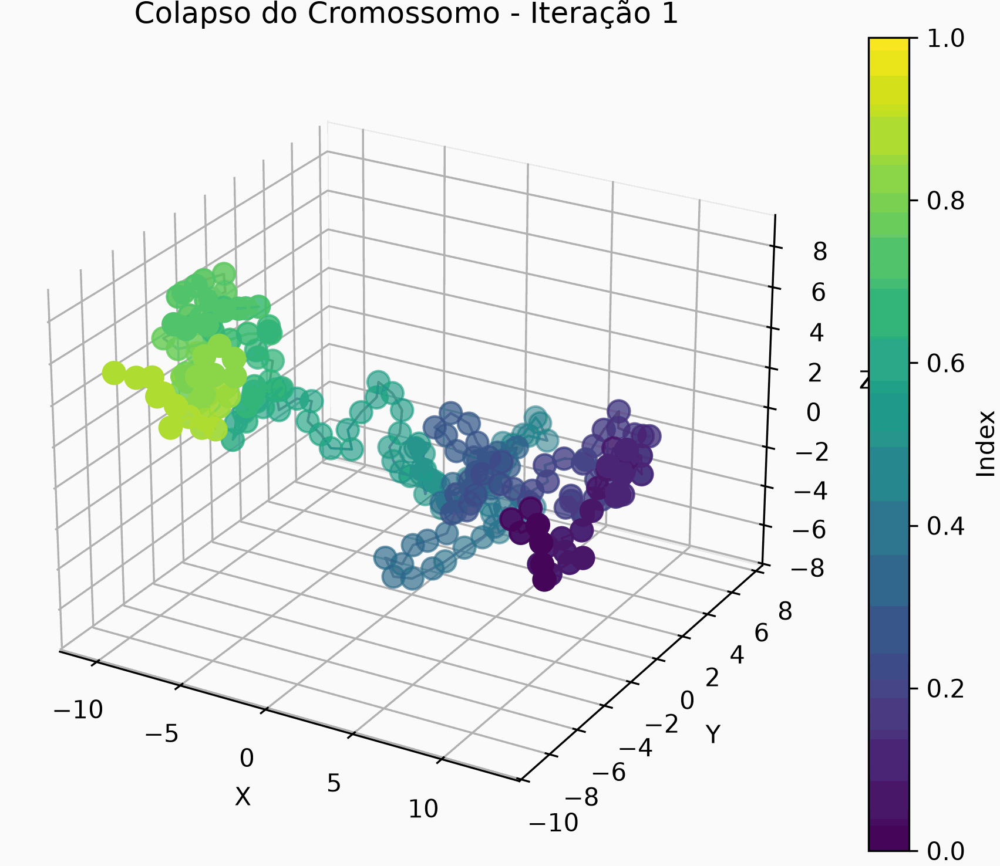

In [13]:
# Diretório onde as imagens estão salvas
input_dir = "gif_colapso"
output_gif = "animação_colapso.gif"

# Coletar os arquivos de imagem ordenados
image_files = sorted([os.path.join(input_dir, f) for f in os.listdir(input_dir) if f.endswith(".png")])

# Criar efeito boomerang duplicando e invertendo os frames
boomerang_frames = image_files + image_files[::-1]  # Vai e volta

# Criar o GIF animado com efeito boomerang
with imageio.get_writer(output_gif, mode="I", duration=0.2, loop=0) as writer:
    for file in boomerang_frames:
        image = imageio.imread(file)
        writer.append_data(image)

print(f"GIF boomerang do colapso salvo como: {output_gif}")
Image(data=output_gif, width=500, height=500)

In [14]:
# Remove o potencial que colapsa o cromossomo
sim_chr10.removeFlatBottomHarmonic()

# Define parâmetros para execução da simulação
block = 10**3 # Tamanho da simulação
n_blocks = 120

# Criar diretório para salvar imagens
output_dir = "gif_simulacao"
os.makedirs(output_dir, exist_ok=True)

# Adiciona um repórter para salvar a trajetória em um arquivo de formato CNDB na segunda fase de simulação
sim_chr10.createReporters(statistics=True, traj=True, trajFormat="cndb")

# Executa a simulação
for i in range(n_blocks):
  sim_chr10.run(nsteps=block, report=False)

  if i % 3 == 0:
    # Obter estado atual da simulação
    state = sim_chr10.context.getState(getPositions=True)
    positions = state.getPositions(asNumpy=True) / unit.nanometers  # Converter para nanômetros

    # Extrair coordenadas
    x, y, z = zip(*positions)

    # Criar a figura 3D
    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection='3d')

    # Criar colormap
    cmap = plt.cm.viridis
    colors = cmap(range(len(x)))

    # Plotar pontos
    ax.scatter(x, y, z, c=colors, marker='o', s=80)
    ax.plot(x, y, z, color='gray', linewidth=1)

    # Configurar limites
    ax.set_xlim(-10, 10)
    ax.set_ylim(-10, 10)
    ax.set_zlim(-10, 10)

    # Adicionar barra de cores
    sm = ScalarMappable(cmap=cmap)
    sm.set_array([])
    fig.colorbar(sm, ax=ax, label='Index')

    # Personalizar gráfico
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    ax.set_title(f'Colapso do Cromossomo - Iteração {i+1}')
    ax.view_init(elev=25, azim=-60)

    # Salvar imagem na pasta gif_colapso
    filename = os.path.join(output_dir, f"frame_{i:03d}.png")
    fig.savefig(filename, bbox_inches='tight', pad_inches=0, dpi=300)
    plt.close(fig)  # Fechar figura para evitar consumo excessivo de memória

print("Imagens salvas! Pronto para criar um GIF.")

Removed FlatBottomHarmonic from the system!
Imagens salvas! Pronto para criar um GIF.


/var/folders/rh/4gjp74rj2yv3fgs9h60cjnhm0000gn/T/ipykernel_87462/1803618409.py:14: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  image = imageio.imread(file)


GIF boomerang do colapso salvo como: animacao.gif


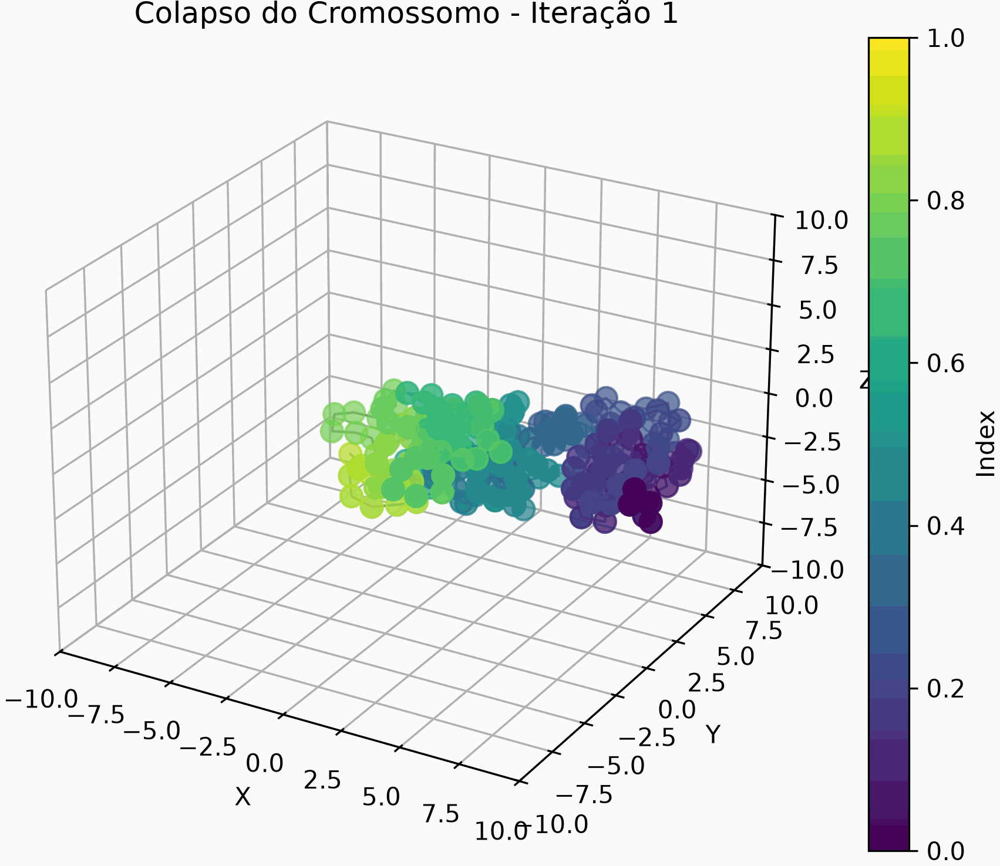

In [15]:
# Diretório onde as imagens estão salvas
input_dir = "gif_simulacao"
output_gif = "animacao.gif"

# Coletar os arquivos de imagem ordenados
image_files = sorted([os.path.join(input_dir, f) for f in os.listdir(input_dir) if f.endswith(".png")])

# Criar efeito boomerang duplicando e invertendo os frames
boomerang_frames = image_files + image_files[::-1]  # Vai e volta

# Criar o GIF animado com efeito boomerang
with imageio.get_writer(output_gif, mode="I", duration=0.2, loop=0) as writer:
    for file in boomerang_frames:
        image = imageio.imread(file)
        writer.append_data(image)

print(f"GIF boomerang do colapso salvo como: {output_gif}")
Image(data=output_gif, width=500, height=500)

Generating the contact probability matrix...
Reading frame 0 of 120


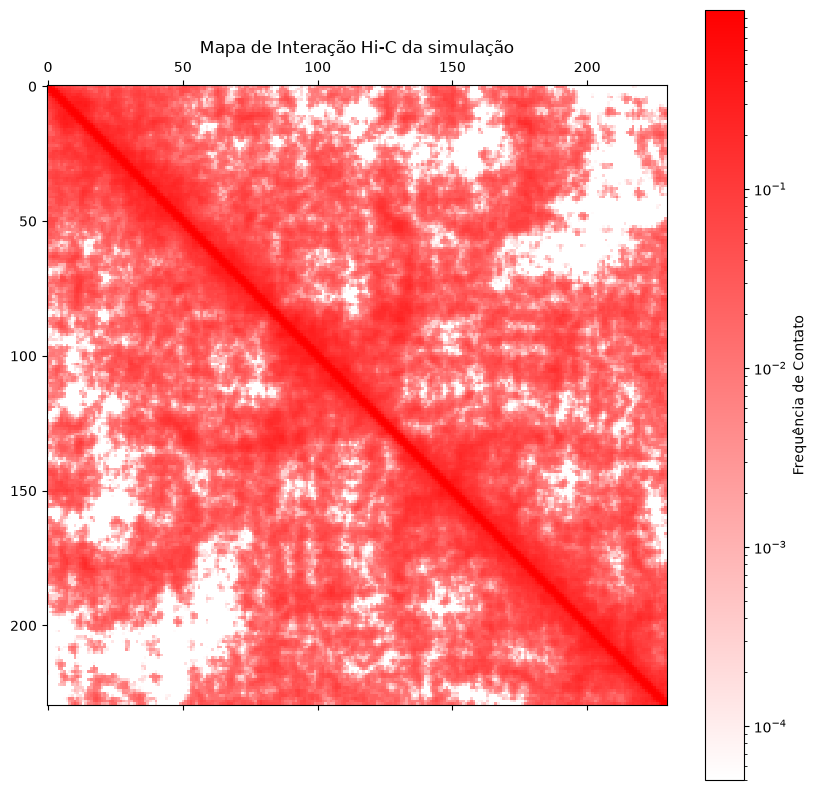

In [18]:
# Etapa de análise de resultados
# chr10_traj = cndbTools.load('/content/output_chr10/chr10_0.cndb')
chr10_traj = cndbTools.load('output_chr10/chr10_0.cndb')
first_frame = min([int(key) for key in chr10_traj.cndb.keys() if key != 'types'])
last_frame = max([int(key) for key in chr10_traj.cndb.keys() if key != 'types'])

chr10_xyz = cndbTools.xyz(frames=list(range(first_frame, last_frame + 1)), XYZ=[0, 1, 2])

# Criando colormap personalizado (azul → branco → vermelho)
vmax = chr10_xyz.max()
vmin = 0.00005

# colors = [[0, "blue"],  # Mínimo
#           [0.5, "white"],  # Valor intermediário
#           [1, "red"]]  # Máximo

colors = [[0, "white"],  # Mínimo
          [1, "red"]]  # Máximo


cmap = mpl.colors.LinearSegmentedColormap.from_list("custom_cmap", colors)

# Gerando Hi-C com ajuste de tamanho
print("Generating the contact probability matrix...")
fig, ax = plt.subplots(figsize=(10, 10))  # Ajuste de tamanho

chr10_sim_HiC = cndbTools.traj2HiC(chr10_xyz)
im = ax.matshow(chr10_sim_HiC, norm=mpl.colors.LogNorm(vmin=vmin, vmax=chr10_sim_HiC.max()), cmap=cmap)
fig.colorbar(im, label="Frequência de Contato")
ax.set_title("Mapa de Interação Hi-C da simulação")

plt.show()

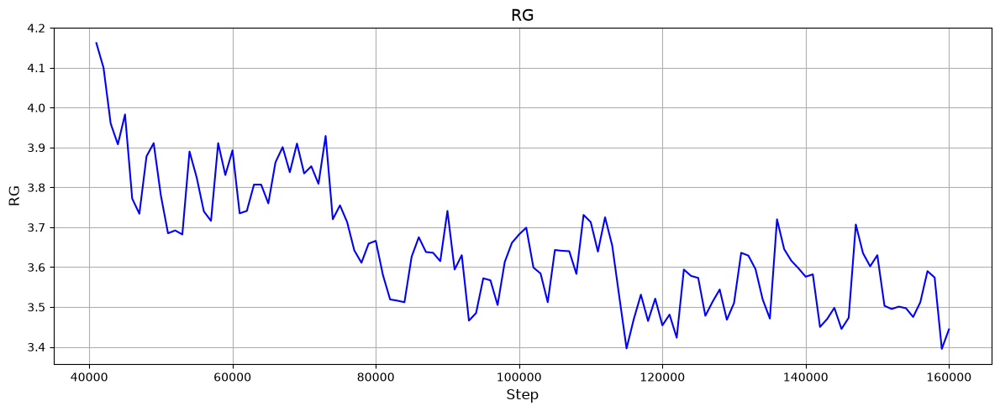

In [19]:
# Gerando gráfico de raio de giro
# Abrindo arquivo com os dados
# file_path = "/content/output_chr10/statistics.txt"
file_path = "output_chr10/statistics.txt"

# Carregar dados do arquivo ignorando comentários (#)
data = np.genfromtxt(file_path, delimiter=',', comments='#', names=True)

coluna = 'RG'
# Extração dos valores de Step e Temperature
steps = data['Step']
temperature = data[coluna]

# Criar o gráfico
plt.figure(figsize=(12, 5))
plt.plot(steps, temperature, linestyle='-', color='blue')
plt.xlabel('Step', fontsize=12)
plt.ylabel(coluna, fontsize=12)
plt.title(coluna, fontsize=14)
plt.grid(True)
plt.tight_layout()

# Exibir o gráfico
plt.show()

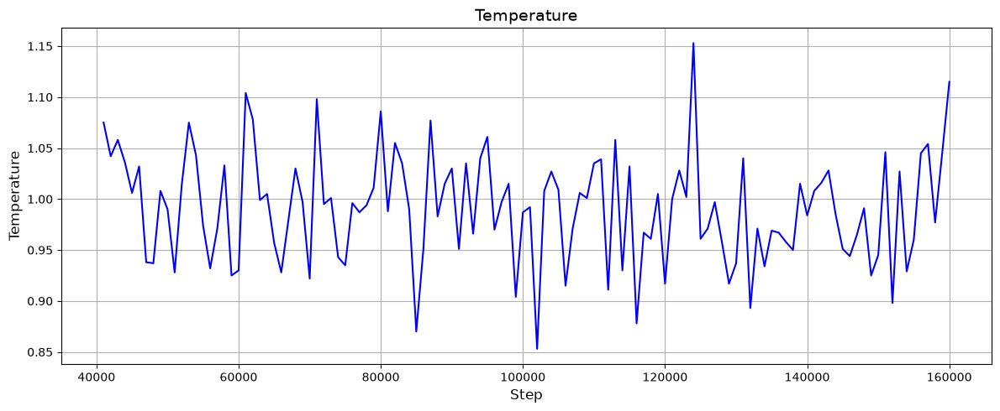

In [20]:
# Gerando gráfico de temperatura
coluna = 'Temperature'
# Extração dos valores de Step e Temperature
steps = data['Step']
temperature = data[coluna]

# Criar o gráfico
plt.figure(figsize=(12, 5))
plt.plot(steps, temperature, linestyle='-', color='blue')
plt.xlabel('Step', fontsize=12)
plt.ylabel(coluna, fontsize=12)
plt.title(coluna, fontsize=14)
plt.grid(True)
plt.tight_layout()

# Exibir o gráfico
plt.show()

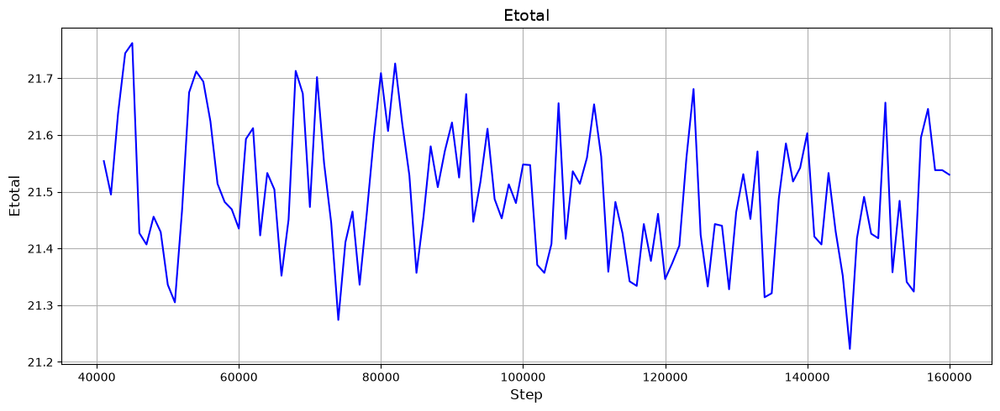

In [21]:
# Gerando gráfico de temperatura
coluna = 'Etotal'
# Extração dos valores de Step e Temperature
steps = data['Step']
temperature = data[coluna]

# Criar o gráfico
plt.figure(figsize=(12, 5))
plt.plot(steps, temperature, linestyle='-', color='blue')
plt.xlabel('Step', fontsize=12)
plt.ylabel(coluna, fontsize=12)
plt.title(coluna, fontsize=14)
plt.grid(True)
plt.tight_layout()

# Exibir o gráfico
plt.show()

(0.3, 4.0)

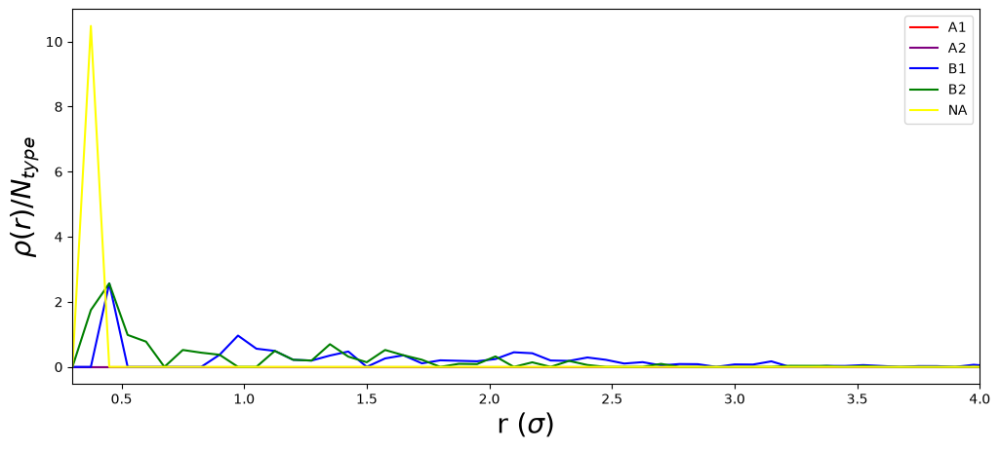

In [22]:
chr10_A1 = cndbTools.xyz(frames=[first_frame,last_frame,1], beadSelection=chr10_traj.dictChromSeq[b'A1'], XYZ=[0,1,2])
chr10_A2 = cndbTools.xyz(frames=[first_frame,last_frame,1], beadSelection=chr10_traj.dictChromSeq[b'A2'], XYZ=[0,1,2])
chr10_B1 = cndbTools.xyz(frames=[first_frame,last_frame,1], beadSelection=chr10_traj.dictChromSeq[b'B1'], XYZ=[0,1,2])
chr10_B2 = cndbTools.xyz(frames=[first_frame,last_frame,1], beadSelection=chr10_traj.dictChromSeq[b'B2'], XYZ=[0,1,2])
chr10_NA = cndbTools.xyz(frames=[first_frame,last_frame,1], beadSelection=chr10_traj.dictChromSeq[b'NA'], XYZ=[0,1,2])

# Função para filtrar índices inválidos
def filtra_indices(beadSelection, total_beads):
    return [i for i in beadSelection if i < total_beads]

# Parâmetros iniciais
radius = 15.0
bins = 200

# Obtenção dos dados para A1 e B1
# Substitua `chr10_traj.dictChromSeq[b'A1']` e `chr10_traj.dictChromSeq[b'B1']` pelos dados corretos
beadSelection_A1 = chr10_traj.dictChromSeq[b'A1']
beadSelection_A2 = chr10_traj.dictChromSeq[b'A2']
beadSelection_B1 = chr10_traj.dictChromSeq[b'B1']
beadSelection_B2 = chr10_traj.dictChromSeq[b'B2']
beadSelection_NA = chr10_traj.dictChromSeq[b'NA']

#"b'A2', b'NA', b'B3', b'B1', b'A1', b'B2'"
# Obtendo os arrays tridimensionais
chr10_A1 = cndbTools.xyz(frames=[first_frame,last_frame,1], beadSelection=beadSelection_A1, XYZ=[0, 1, 2])
chr10_A2 = cndbTools.xyz(frames=[first_frame,last_frame,1], beadSelection=beadSelection_A2, XYZ=[0, 1, 2])
chr10_B1 = cndbTools.xyz(frames=[first_frame,last_frame,1], beadSelection=beadSelection_B1, XYZ=[0, 1, 2])
chr10_B2 = cndbTools.xyz(frames=[first_frame,last_frame,1], beadSelection=beadSelection_B2, XYZ=[0, 1, 2])
chr10_NA = cndbTools.xyz(frames=[first_frame,last_frame,1], beadSelection=beadSelection_NA, XYZ=[0, 1, 2])

# Filtra os índices inválidos
beadSelection_A1_validos = filtra_indices(beadSelection_A1, chr10_A1.shape[1])
beadSelection_A2_validos = filtra_indices(beadSelection_A2, chr10_A1.shape[1])
beadSelection_B1_validos = filtra_indices(beadSelection_B1, chr10_B1.shape[1])
beadSelection_B2_validos = filtra_indices(beadSelection_B2, chr10_B1.shape[1])
beadSelection_NA_validos = filtra_indices(beadSelection_NA, chr10_NA.shape[1])

# Calculando o RDP para A1
r_A1, RDP_chr10_A1 = cndbTools.compute_RDP(
    chr10_A1, beadSelection=beadSelection_A1_validos, radius=radius, bins=bins
)

# Calculando o RDP para A2
r_A2, RDP_chr10_A2 = cndbTools.compute_RDP(
    chr10_A2, beadSelection=beadSelection_A2_validos, radius=radius, bins=bins
)

# Calculando o RDP para B1
r_B1, RDP_chr10_B1 = cndbTools.compute_RDP(
    chr10_B1, beadSelection=beadSelection_B1_validos, radius=radius, bins=bins
)

# Calculando o RDP para B2
r_B2, RDP_chr10_B2 = cndbTools.compute_RDP(
    chr10_B2, beadSelection=beadSelection_B2_validos, radius=radius, bins=bins
)

# Calculando o RDP para NA
r_NA, RDP_chr10_NA = cndbTools.compute_RDP(
    chr10_NA, beadSelection=beadSelection_NA_validos, radius=radius, bins=bins
)

plt.figure(figsize=(12, 5))
plt.plot(r_A1, RDP_chr10_A1, color='red', label='A1')
plt.plot(r_A2, RDP_chr10_A2, color='purple', label='A2')
plt.plot(r_B1, RDP_chr10_B1, color='blue', label='B1')
plt.plot(r_B2, RDP_chr10_B2, color='green', label='B2')
plt.plot(r_NA, RDP_chr10_NA, color='yellow', label='NA')
plt.xlabel(r'r ($\sigma$)', fontsize=20,fontweight='normal', color='k')
plt.ylabel(r'$\rho(r)/N_{type}$', fontsize=20,fontweight='normal', color='k')
plt.legend()
plt.gca().set_xlim(xmin=0.3,xmax=4)

In [23]:
# Definir o caminho de saída para os arquivos
# path_to_cndb = "/content/output_chr10/"
path_to_cndb = "output_chr10/"
file_name = "chr10_0"

# Mapeamento dos tipos de resíduos para o formato PDB
Type_conversion = {'A1': 'ASP', 'A2': 'GLU', 'B1': 'LYS', 'B2': 'ARG', 'B3': 'HIS', 'B4': 'HIS', 'NA': 'GLY'}

# Selecionar o primeiro frame para o PDB
frame = 0  # Ajuste conforme necessário

# Gerar o arquivo PDB
pdb_path = f"{path_to_cndb}{file_name}.pdb"
with open(pdb_path, "w") as f:
    for i in range(len(chr10_xyz[frame])):
        j = ['' for _ in range(9)]
        j[0] = 'ATOM'.ljust(6)
        j[1] = str(i + 1).rjust(5)
        j[2] = 'CA'.center(4)

        # Corrigir conversão de bytes para string antes de acessar Type_conversion
        residue_name = chr10_traj.ChromSeq[i].decode("utf-8") if isinstance(chr10_traj.ChromSeq[i], bytes) else chr10_traj.ChromSeq[i]
        j[3] = Type_conversion.get(residue_name, 'GLY').ljust(3)  # Usa 'GLY' como padrão caso não esteja no dicionário

        j[4] = 'A'.rjust(1)
        j[5] = str(i + 1).rjust(4)
        j[6] = str('%8.3f' % float(chr10_xyz[frame][i][0])).rjust(8)
        j[7] = str('%8.3f' % float(chr10_xyz[frame][i][1])).rjust(8)
        j[8] = str('%8.3f' % float(chr10_xyz[frame][i][2])).rjust(8)
        f.write("{}{} {} {} {}{}    {}{}{}\n".format(*j))
    f.write("END\n")

# Carregar e salvar a trajetória em XTC
traj = md.load(pdb_path)
traj.xyz = chr10_xyz
traj.time = np.linspace(0, len(chr10_xyz), len(chr10_xyz))
traj.save_xtc(f"{path_to_cndb}{file_name}.xtc")

print("Arquivos PDB e XTC gerados com sucesso para visualização em seu computador")

Arquivos PDB e XTC gerados com sucesso para visualização em seu computador


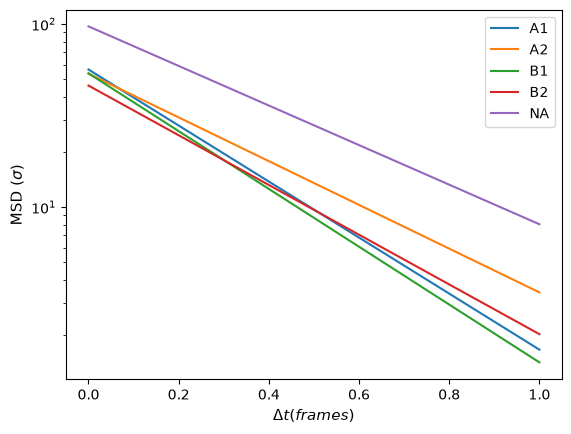

In [25]:
#4.8 Diffusivity of A1 and B1
import numpy as np
MSD_A1=np.mean(cndbTools.compute_MSD(chr10_A1),axis=0)[1:]
MSD_A2=np.mean(cndbTools.compute_MSD(chr10_A2),axis=0)[1:]
MSD_B1=np.mean(cndbTools.compute_MSD(chr10_B1),axis=0)[1:]
MSD_B2=np.mean(cndbTools.compute_MSD(chr10_B2),axis=0)[1:]
MSD_NA=np.mean(cndbTools.compute_MSD(chr10_NA),axis=0)[1:]
plt.plot(MSD_A1,label='A1')
plt.plot(MSD_A2,label='A2')
plt.plot(MSD_B1,label='B1')
plt.plot(MSD_B2,label='B2')
plt.plot(MSD_NA,label='NA')
plt.ylabel(r'MSD ($\sigma$)', fontsize=11,fontweight='normal', color='k')
plt.xlabel(r'$\Delta t (frames)$', fontsize=11,fontweight='normal', color='k')
plt.yscale('log')
plt.legend()